В этом ноутбуке описан пайплайн полного процесса валидации с использованием библиотеки llm_val. 

## 0. Получение данных, взгляд на данные.

Предположим, что вам уже переданы данные для валидации, и у нас есть только тестовая выборка:

In [1]:
import sys
import joblib
import numpy as np
import pandas as pd

sys.path.append('src') # Будем импортировать некоторые файлы из библиотеки для проведения валидации

In [2]:
data = pd.read_parquet('examples/data/data_ft_full.parquet')

In [3]:
data.head(5)

,session_id,final_metric_asessor_1,final_metric_asessor_2,final_metric_asessor_3,final_metric_asessor_4,final_metric_asessor_5,estimation,query_id,input_query,output_answer
0,0,1.0,NaN,NaN,NaN,1.0,1,b50744e833cefe610331f3d26210ace6,Расскажи о состоянии портфеля за месяц,Стоимость портфеля за ноябрь-декабрь 2025 года...
1,1,NaN,NaN,NaN,0.0,1.0,0,6bca9eec0de89a8dab6b1f77bb1116a5,анализ моего портфеля за 25 год,"К сожалению, из-за технических проблем не удал..."
2,2,1.0,NaN,0.0,NaN,NaN,0,d1de6397ed80dec217cd79a0ca5fb742,инвесткопилка,В вашем портфеле отсутствуют данные о продукте...
3,3,1.0,1.0,NaN,NaN,NaN,1,5908a95011350ff5ce48585d528d6d54,Фонд Рублевые сбережения,"В вашем портфеле отсутствуют данные о фонде ""Р..."
4,4,NaN,1.0,NaN,NaN,1.0,1,486cdbf61e53fb5a97726d7bcaa4b359,Структура портфеля и риски,Основные характеристики портфеля:\n- Общий объ...


Видим какие-то данные с результатами разметки асессорами. 

У УМР есть требования к формату тестового датасета, передаваемого на валидацию. Выглядят они так:

- ***Отдельные запросы***:
    1. `session_id` - Идентификатор сессии взаимодействия пользователя с агентом. `Union[int, uuid]`;
    2. `query_id` - Идентификатор отдельного запроса пользователя. `Union[int, str, uuid]`;
    3. `input_query` - Текст запроса в GenAI-решение. `str`;
    4. `output_answer` - Текст ответа GenAI-решения на входной запрос. `str`;
    5. `reference_answer` - Истинный ответ (ground truth) или ответ, на который стоит ориентироваться при оценке качества ответа от GenAI-решения. `str` (N.B. Если таких возможно несколько на один запрос, то нужно использовать нейминг `reference_answer_1`, `reference_answer_2`, ...);
    6. `[metric_name]_metric` - Значение метрики качества или критерия оценки `metric_name`, проставляемой одним асессором для ответа GenAI-решения. `float`;
    7. `[module_name]_input_query` - Текст запроса в конкретный модуль `module_name` GenAI-решение. `str`;
    8. `[module_name]_output_answer` - Текст ответа от конкретного модуля `module_name` GenAI-решения на входной запрос. `str`;
    9. `[module_name]_reference_answer` - Истинный ответ (ground truth) или ответ, на который стоит ориентироваться при оценке качества ответа от конкретного модуля `module_name` GenAI-решения. `str` (N.B. Нейминг для нескольких ответов аналогичен `reference_answer` выше);
    10. `[module_name]_[metric_name]_metric` - Значение метрики качества или критерия оценки, проставляемой одним асессором для ответа от конкретного модуля `module_name` GenAI-решения. `float`;
    11. `assessor_id` - идентификатор асессора. `Union[int, uuid]`;
    12. `scenario` - Тематика запроса / уровень сложности запроса / название тестового сценария / другие классифицирующие запрос характеристики. `str`.
    
    
- ***Диалог***:
    1. `session_id` - Идентификатор сессии взаимодействия пользователя с агентом. `Union[int, uuid]`;
    2. `dialogue` - Полный текст диалога между пользователей и GenAI-решением в рамках сессии. Представим как список из кортежей, где каждый кортеж имеет вид `(str, str, str)`. В каждом кортеже есть строки - `query_id`, `input_query`, `output_answer`. `List[(str, str, str)]`;
    3. `[metric_name]_metric` - Значение метрики качества или критерия оценки `metric_name`, проставляемой одним асессором для ответа GenAI-решения. `float`;
    4. `assessor_id` - идентификатор асессора. `Union[int, uuid]`;
    5. `scenario` - Тематика запроса / уровень сложности запроса / название тестового сценария / другие классифицирующие запрос характеристики. `str`.

Ожидается, что разработчики должны передавать данные именно так, но к сожалению, это не всегда верно.

Для проведения валидации с использованием библиотеки llm_val до запуска тестов требуется подготовить две сущности: Sampler и Scorer.

Первый будет хранить в себе данные в формате, требуемом библиотекой (этот формат практически копирует формат выше), второй нужен для подсчета метрик по имеющимся данным.

## 1. Написание Sampler'a.

Чтобы не писать тесты в библиотеке каждый раз заново под разную структуру данных, а запускать тесты "из коробки", необходимо привести свои данные к единому формату, который ожидают на вход все тесты. 

Фактически наша задача состоит в том, чтобы перегнать сырые данные от разработчиков в ожидаемый библиотекой формат. Для этого нам требуется:

### Создать стандартную обертку для Sampler'a

Любой сэмплер, используемый вами, должен быть отнаследован от стандартного класса Sampler из библиотеки. Делается это просто:

In [4]:
from llm_val.sampler.Sampler import Sampler

class MySampler(Sampler):
    def __init__(self, 
                 test: pd.DataFrame):
        pass

Конструктор класса принимает в себя только имеющиеся у вас выборки (предполагается, что тестовая выборка у вас точно есть, так что всегда ожидается хотя бы поле `test`).

Если у вас есть какие-то другие выборки, то в классе `Sampler` также доступны поля `train`, `val`, `oot`.

### Преобразовать данные от разработчиков в данные для проведения тестов

Было бы удобно, если бы после написания кода преобразования можно было просто подать в сэмплер датафрейм с данными, и он сразу создал все необходимые выборки. В связи с этим немного улучшим сэмплер: 

In [5]:
from llm_val.sampler.Sampler import Sampler

class MySampler(Sampler):
    def __init__(self, 
                 test: pd.DataFrame):
        test = self._preproc(test)
        super().__init__(test=test)
        
    def _preproc(self, 
                 var: pd.DataFrame):
        pass

Осталось реализовать основную функцию - `_preproc`.

Что мы хотим на выходе этой функции?

Любой сэмплер хранит в себе данные в формате словарей с ключами `X`, `y` и `traces` (при наличии), содержащими в себе pd.DataFrame, например:

```python
MySampler.test = {'X': pd.DataFrame,
                  'y': pd.DataFrame,
                  'traces': pd.DataFrame}
```

Итак, функция `_preproc` должна вернуть из себя словарь вида 
```python
{'X': pd.DataFrame,
 'y': pd.DataFrame,
 'traces': pd.DataFrame}
```
, где последнее поле - опционально (например, в нашем примере у нас трейсов нет).

Следующий вопрос - что же должно содержаться в этом словаре, а точнее - в датафреймах этого словаря?

Вообще говоря, большая часть наших потребностей закрываются уже имеющимися форматом тестового датасета и форматом трейсов, которые мы предоставляем контрагентам.

Каких-то колонок у вас может не быть, и это *нормально* - например, у вас может не быть метрик по отдельным модулям, и это нормально, в таком случае вы просто не проведете тесты, проверяющие качество отдельных модулей. 

N.B. На всякий случай уточню, что сэмплер для проведения всех тестов у вас всегда *один*. Он может содержать несколько ключей: `X`, `y` и `traces` (как написано выше), а все требуемые колонки для какого-то ключа просто запихиваются в датафрейм.

Максимальный список столбцов, ожидаемых в сэмплере:

**Отдельные запросы**:
- ***X***
    1. `session_id` - Идентификатор сессии взаимодействия пользователя с агентом. `Union[int, uuid]`;
    2. `query_id` - Идентификатор отдельного запроса пользователя. `Union[int, str, uuid]`;
    3. `input_query` - Текст запроса в GenAI-решение. `str`;
    4. `output_answer` - Текст ответа GenAI-решения на входной запрос. `str`;
    5. `reference_answer` - Истинный ответ (ground truth) или ответ, на который стоит ориентироваться при оценке качества ответа от GenAI-решения. `str` (N.B. Если таких возможно несколько на один запрос, то нужно использовать нейминг `reference_answer_1`, `reference_answer_2`, ...);
    6. `[metric_name]_metric` - Значение метрики качества или критерия оценки `metric_name`, проставляемой одним асессором для ответа GenAI-решения. `float`;
    7. `[module_name]_input_query` - Текст запроса в конкретный модуль `module_name` GenAI-решение. `str`;
    8. `[module_name]_output_answer` - Текст ответа от конкретного модуля `module_name` GenAI-решения на входной запрос. `str`;
    9. `[module_name]_reference_answer` - Истинный ответ (ground truth) или ответ, на который стоит ориентироваться при оценке качества ответа от конкретного модуля `module_name` GenAI-решения. `str` (N.B. Нейминг для нескольких ответов аналогичен `reference_answer` выше);
    10. `[module_name]_[metric_name]_metric` - Значение метрики качества или критерия оценки, проставляемой одним асессором для ответа от конкретного модуля `module_name` GenAI-решения. `float`;
    11. `assessor_id` - идентификатор асессора. `Union[int, uuid]`;
    12. `scenario` - Тематика запроса / уровень сложности запроса / название тестового сценария / другие классифицирующие запрос характеристики. `str`.

- ***y***
    
    **Индекс**: `session_id` - Идентификатор сессии взаимодействия пользователя с агентом. `Union[int, uuid]`;
    1. `[metric_name]_metric` - Посчитанная метрика качества `metric_name` на конкретном вопросе: либо агрегированный результат столбца `[metric_name]_metric` в ***X***, либо посчитанная автоматически. `Union[float, int]`.

**Диалог**:
- ***X***
    1. `session_id` - Идентификатор сессии взаимодействия пользователя с агентом. `Union[int, uuid]`;
    2. `dialogue` - Полный текст диалога между пользователей и GenAI-решением в рамках сессии. Представим как список из кортежей, где каждый кортеж имеет вид `(str, str, str)`. В каждом кортеже есть строки - `query_id`, `input_query`, `output_answer`. `List[(str, str, str)]`;
    3. `[metric_name]_metric` - Значение метрики качества или критерия оценки `metric_name`, проставляемой одним асессором для ответа GenAI-решения. `float`;
    4. `assessor_id` - идентификатор асессора. `Union[int, uuid]`; 
    5. `scenario` - Тематика запроса / уровень сложности запроса / название тестового сценария / другие классифицирующие запрос характеристики. `str`.
    
- ***y***
    
    **Индекс**: `session_id` - Идентификатор сессии взаимодействия пользователя с агентом. `Union[int, uuid]`;
    1. `[metric_name]_metric` - Посчитанная метрика качества `metric_name` на конкретном вопросе: либо агрегированный результат столбца `[metric_name]_metric` в ***X***, либо посчитанная автоматически. `Union[float, int]`.

**Трейсы** - опционально можно добавить в сэмплер для любого формата датасета.
- ***X***, ***y***: описано в других пунктах;
- ***traces***:
    1. `trace_id` - id трейса, соответствующее одному диалогу/запросу. `Union[int, uuid]`;
    2. `span_id` - id спана, соответствующее одной ноде/инструменту агента. `Union[int, uuid]`;
    3. `span_name` - название ноды/инструмента агента. `str`;
    4. `start_time_ns` - время начала работы ноды агента в unix-формате. `datetime64[ns]`;
    5. `end_time_ns` - время окончания работы ноды агента в unix-формат. `datetime64[ns]`;
    6. `session_id` - (идентично полю в `X`) - идентификатор сессии взаимодействия пользователя с агентом. `Union[int, uuid]`.
    
**RAG**:
- ***X***:
    1. `session_id` - Идентификатор сессии взаимодействия пользователя с агентом. `Union[int, uuid]`;
    2. `query_id` - Идентификатор отдельного запроса пользователя. `Union[int, str, uuid]`;
    3. `input_query` - Текст запроса в GenAI-решение. `str`;
    4. `output_answer` - Текст ответа GenAI-решения на входной запрос. `str`;
    5. `reference_answer` - Истинный ответ (ground truth) или ответ, на который стоит ориентироваться при оценке качества ответа от GenAI-решения. `str` (N.B. Если таких возможно несколько на один запрос, то нужно использовать нейминг `reference_answer_1`, `reference_answer_2`, ...);
    6. `[metric_name]_metric` - Значение метрики качества или критерия оценки `metric_name`, проставляемой одним асессором для ответа GenAI-решения. `float`;
    7. `passage_accuracy` - Словарь с оценками релевантностей пассажей. `Dict[Union[str, int], List[int]]`;
    8. `scenario` - Тематика запроса / уровень сложности запроса / название тестового сценария / другие классифицирующие запрос характеристики. `str`.

- ***y***

    **Индекс**: `session_id` - Идентификатор сессии взаимодействия пользователя с агентом. `Union[int, uuid]`;
    1. `sim_<название_расстояния>` - Расстояния от вопроса до пассажей. Размер списка n, где n - количество пассажей. `List[float]`;
    2. `[metric_name]_metric` - Посчитанная метрика качества `metric_name` на конкретном вопросе: либо агрегированный результат столбца `[metric_name]_metric` в ***X***, либо посчитанная автоматически. `Union[float, int]`.

Итак, попробуем по возможности заполнить все колонки для сэмплера. Агрегацию меток проведем методом Дэвида-Скина.

In [13]:
import typing as tp
import pandas as pd
from crowdkit.aggregation import DawidSkene

from llm_val.sampler.Sampler import Sampler

class MySampler(Sampler):
    '''
    Семплер для данных FastTrack.
    Преобразует wide-формат (assessor_1..N в колонках) в long-формат
    и агрегирует метки асессоров с помощью алгоритма Дэвида-Скина.
    '''
    def __init__(self,
                 test: pd.DataFrame,
                 n_iter: int=100):
        '''
        Parameters:
            test: Тестовый набор данных в wide-формате
            n_iter: Количество итераций Dawid-Skene
        '''
        test = self._preproc(test, 
                             n_iter)
        super().__init__(test=test)

    def _preproc(self,
                 df: pd.DataFrame,
                 n_iter: int) -> tp.Dict[str, pd.DataFrame]:
        '''
        Преобразование данных из wide-формата в long-формат
        и агрегация меток асессоров с помощью Dawid-Skene
        Parameters:
            df: Исходный DataFrame в wide-формате
            n_iter: Количество итераций Dawid-Skene
        Return:
            Словарь с ключами X и y
        '''
        df= df.copy()
        df['output_answer'] = df['output_answer'].fillna('').astype(str)
        # Нам нужно иметь в одной строке результат разметки одним человеком одного вопроса
        # Выделим колонки с разметкой асессоров и и переведем их в нужный формат
        assessor_groups, other_columns = self._split_columns(df)
        x_data = self._wide_to_long(df, 
                                    assessor_groups, 
                                    other_columns)
        # Выделим колонки с метрикой (здесь такая одна) и агрегируем их методом Дэвида-Скина 
        metric_columns = [col for col in x_data.columns
                          if col.endswith('_metric')]
        y_data = self._aggregate_dawid_skene(x_data, 
                                             metric_columns, 
                                             n_iter)
        return {'X': x_data, 'y': y_data}

    def _split_columns(self,
                       df: pd.DataFrame) -> tp.Tuple[tp.Dict, tp.List[str]]:
        '''
        Разделение колонок на группы асессоров и прочие колонки
        Parameters:
            df: Исходный DataFrame
        Return:
            Кортеж из словаря групп асессоров и списка прочих колонок
        '''
        assessors = {}
        other_columns = []
        for column in df.columns:
            if 'asessor' in column:
                assessor_key = column[column.find('asessor'):]
                assessors[assessor_key] = assessors.get(assessor_key, []) + [column]
            elif column != 'estimation':
                other_columns.append(column)
        return assessors, other_columns

    def _wide_to_long(self,
                      df: pd.DataFrame,
                      assessor_groups: tp.Dict[str, tp.List[str]],
                      other_columns: tp.List[str]) -> pd.DataFrame:
        '''
        Преобразование wide-формата в long-формат
        Parameters:
            df: Исходный DataFrame
            assessor_groups: Словарь с группами колонок по асессорам
            other_columns: Список прочих колонок
        Return:
            DataFrame в long-формате с колонкой assessor_id
        '''
        agg_data = []
        for assessor_key in assessor_groups:
            curr_df = pd.DataFrame()
            for column in assessor_groups[assessor_key]:
                metric_name = column.split('_asessor')[0]
                curr_df[metric_name] = df[column]
            curr_df['assessor_id'] = assessor_key.split('_')[-1]
            agg_data.append(pd.concat([curr_df, df[other_columns]], axis=1))
        return pd.concat(agg_data, axis=0).reset_index(drop=True)

    def _aggregate_dawid_skene(self,
                               x_data: pd.DataFrame,
                               metric_columns: tp.List[str],
                               n_iter: int) -> pd.DataFrame:
        '''
        Агрегация меток асессоров с помощью Dawid-Skene
        Parameters:
            x_data: DataFrame в long-формате
            metric_columns: Список колонок с метриками
            n_iter: Количество итераций Dawid-Skene
        Return:
            DataFrame с агрегированными метками по session_id
        '''
        y_data = pd.DataFrame()
        for metric_col in metric_columns:
            long_df = x_data[['session_id', 'assessor_id', metric_col]].dropna(
                subset=[metric_col])
            long_df = long_df.rename(columns={'session_id': 'task',
                                              'assessor_id': 'worker',
                                              metric_col: 'label'})
            long_df['label'] = long_df['label'].astype(int)
            model = DawidSkene(n_iter=n_iter)
            y_data[metric_col] = model.fit_predict(long_df)
        y_data.index.name = 'session_id'
        return y_data

Сэмплер готов!

In [14]:
my_sampler = MySampler(data)

In [15]:
my_sampler.test['X']

,final_metric,assessor_id,session_id,query_id,input_query,output_answer
0,1.0,1,0,b50744e833cefe610331f3d26210ace6,Расскажи о состоянии портфеля за месяц,Стоимость портфеля за ноябрь-декабрь 2025 года...
1,NaN,1,1,6bca9eec0de89a8dab6b1f77bb1116a5,анализ моего портфеля за 25 год,"К сожалению, из-за технических проблем не удал..."
2,1.0,1,2,d1de6397ed80dec217cd79a0ca5fb742,инвесткопилка,В вашем портфеле отсутствуют данные о продукте...
3,1.0,1,3,5908a95011350ff5ce48585d528d6d54,Фонд Рублевые сбережения,"В вашем портфеле отсутствуют данные о фонде ""Р..."
4,NaN,1,4,486cdbf61e53fb5a97726d7bcaa4b359,Структура портфеля и риски,Основные характеристики портфеля:\n- Общий объ...
...,...,...,...,...,...,...
1235,NaN,5,243,d7ae8b735f5c05756f6e733727a31d8c,Анализ финансов,В вашем портфеле отсутствуют необходимые данны...
1236,1.0,5,244,a5840b09581dad80c86eb77cc6694d54,накопител,В вашем портфеле отсутствуют необходимые данны...
1237,NaN,5,245,d566e18cbe236411702622a064e28641,Анализ финансов,В вашем портфеле отсутствуют необходимые данны...
1238,NaN,5,246,a59ec9ee8bc680e2fd28ddf5ecab8c2b,Фонд Рублевые сбережения,"Фонд ""Рублевые сбережения"" отсутствует в вашем..."


In [16]:
my_sampler.test['y']

,final_metric
session_id,
0,1
2,1
3,1
7,0
8,1
...,...
178,1
179,0
185,1


## 2. Написание (переиспользование?) Scorer'a, написание метрик.

После предыдущего шага мы уже имеем в сэмплере посчитанные скоры/метрики по каждой строчке по каждому критерию по ключу `y`.

Конечно, помимо этого нам нужно считать метрики по всему датасету, и здесь нам пригодится сущность `Scorer`.

Важно: в Scorer-е **НИКОГДА** не происходит подсчет метрик по отдельным объектам; он нужен только для *агрегации* отдельных скоров по объектам с помощью функции метрики! 

В библиотеке уже существует написанный `UniversalScorer`, которого может быть достаточно для многих практических ситуаций. Что он делает?

1) По очереди идет по всем колонкам из `y` или берет все колонки оттуда разом (зависит от параметра `is_singlecol` конкретной метрики, об этом - ниже);

2) Считает метрику функцией, указанной в параметре `call`.

Таким образом, если для подсчета метрики вам нужны только построчные метрики/скоры и ничего больше, то вам вполне достаточно имеющегося скорера.

***Примеры метрик, подходящих для `UniversalScorer`***:
* Усреднение метрик отдельно по колонкам/по всем колонкам сразу;
* `Hit_Rate@k` при *фиксированном* `k` (нужны скоры вида "релевантен/не релевантен", которые могут храниться в `y` в сэмплере, переменная `k` фиксируется на уровне самой функции метрики и отдельным параметром не является).

***Примеры метрик, не подходящих для `UniversalScorer`***:
* `ROC-AUC`/`F1-score`/`Recall` (требует как скоров, так и `true_answer` из `'X'`);
* `Hit_Rate@k` при *переменном* `k` (теперь требуется еще подавать в функцию какой-то параметр, чего не предусмотрено в `UniversalScorer`).

Так как во многих случаях нам нужно обычное усреднение или что-то не сильно сложнее, то сразу перейдем к следующему пункту:

### Реализация метрики

Скорер принимает в себя один параметр - словарь со всеми интересными нам метриками.

Скорер ожидает в себя словарь вида

```python
METRICS = {'metric_name_1': {'call': metric_function_1, 'is_singlecol': True,
           'metric_name_2': {'call': metric_function_2, 'is_singlecol': False,
           ...}
```

Каждый элемент словаря метрик сам является словарем. 

В этом словаре имеются два ключа: 
* `'call'`, в котором указана вызываемая функция;
* `'is_singlecol'` - бинарная переменная, которая указывает, нужно ли брать колонки для подсчета метрики по одной из `y` (таким образом у нас получится `len(y.columns)` значений метрики) или все колонки разом (тогда получится одно значение метрики).

Реализация непосредственно метрик `metric_function` произвольна, вы просто должны понимать, что вам приходит на вход из скорера. В случае `UniversalScorer`  это одна колонка из `y` в случае `is_singlecol == True` и все колонки `y` иначе.

Возвращаясь к нашему примеру: у меня в примере в качестве целевой метрики выступает просто усреднение отдельных меток асессоров по отдельным критериям, поэтому назову свою метрику `single_mean`, а мой скорер с метрикой получается следующим:

In [13]:
from llm_val.scorer.UniversalScorer import UniversalScorer

my_metrics = {'single_mean': {'call': lambda x: np.mean(x.values), 'is_singlecol': True}}

my_scorer = UniversalScorer(metrics=my_metrics)

#### Важно: `UniversalScorer` для `is_singlecol == True` возвращает из себя метрику под названием `названиеметрики_названиекритерия`, а для `is_singlecol == False` - `названиеметрики`.

Таким образом, в нашем примере, где единственный критерий называется `final_metric`, а метрику я назвал `single_mean`, мой скорер выдаст в качестве названия ключа метрики `single_mean_final_metric`. 

### Написание своего Scorer-a

N.B. *При первом ознакомлении с библиотекой эту часть можно пропустить.*

Конечно, у вас могут быть более сложные метрики, чем обычное усреднение, и в таком случае с большой вероятностью необходимо написать свой скорер.



In [14]:
import typing as tp
from llm_val.scorer.Scorer import Scorer

class MyScorer(Scorer):
    def __init__(self,
                 metrics: tp.Dict[str, tp.Callable]):
        super().__init__(metrics)
        
    def calc(self,
             sampler: Sampler,
             data_type: str,
             metric_name: str) -> tp.Dict[str, float]:
        pass

Конструктор скорера и типы данных параметров на вход и выход функции `calc` всегда идентичны и приведены выше. Ваша задача - переопределить функцию `calc`.

Функция `calc` должна 

1) взять какую-то часть датафрейма по ключу `data_type` из сэмплера через `getattr(sampler, data_type)` (можно брать любые колонки как `y`, так и `X`, вы ничем не ограничены!);

2) отдать посчитанную `metric_name` как значение в словаре на выход функции по ключу `metric_name`, а именно:

```python
metric_res = {}
metric_res[metric_name] = self.metrics[metric_name]['call'](data)
return metric_res
```

Приведу пример простейшего реализованного скорера:

In [15]:
class MyScorer(Scorer):
    def __init__(self,
                 metrics: tp.Dict[str, tp.Callable]):
        super().__init__(metrics)

    def calc(self,
             sampler: Sampler,
             data_type: str,
             metric_name: str) -> tp.Dict[str, float]:
        data = getattr(sampler, data_type)['y'] # Пусть мне из сэмплера достаточно только `y` для подсчета метрики
        metrics = self.metrics
        
        metric_res = {}
        if metrics[metric_name]['is_singlecol']:
            # Если использую только одну колонку для подсчета метрики, то хочу посчитать метрику по каждой из колонок
            for name_col in data:
                name = f'{metric_name}_{name_col}'
                metric_res[name] = metrics[metric_name]['call'](data[name_col])
        else:
            # Иначе все пихаем в функцию метрики
            metric_res[metric_name] = metrics[metric_name]['call'](data)
        return metric_res

Скорер готов!

In [16]:
my_scorer = MyScorer(metrics=my_metrics)

## 3. Запуск тестов: по отдельности и по одной кнопке

Теперь, с реализованными сэмплером и скорером, можно проводить тесты из библиотеки. Вы можете проводить их двумя способами:

### Запуск тестов по отдельности

Если вы никогда не пользовались библиотекой или не знаете заранее весь список тестов, которые хотите провести, то это - оптимальный сценарий.

В [ноутбуке 5.2](examples/5.2.All_test_example.ipynb) описаны все тесты, реализованные на текущий момент по методике 20 валидации Gen-AI решений. Нумерация идентична нумерации тестов в методике. 

Если вас интересуют какие-то тесты из устаревших методик 56 и 6, то в [ноутбуке 5.2_archived](examples/5.2.All_test_example_archived.ipynb) реализованы все тесты этапа 2 (миттельшпиля) (они имеют номера 0.X) и этапа 3 (эндшпиля) методики 56, а также некоторые уникальные тесты методики 6 (они идут в методике после тестов методики 56).

Вы находите в ноутбуке необходимый вам тест, смотрите пример его запуска и запускаете его аналогично. Если у автора теста были какие-то комментарии по его проведению, их также можно найти в этом ноутбуке. 

Если вам не понимаете, что вам нужно подавать в каких-либо параметрах, используемых в тесте, то это можно узнать в докстрингах к этому тесту (если ваша IDE не показывает докстринги автоматически, то можно зайти вручную в сам тест и посмотреть там описание переменных; импорт основной функции теста всегда происходит в ноутбуке 5.2).

N.B.: После реализации всех тестов по методике 20 появится отдельный .md-файл, где можно будет увидеть все возможные параметры по всем тестам методики и докстринги к ним.

Попробуем провести какой-нибудь тест, например, тест на согласованность разметчиков (он же по методике "Комплексное качество разметки"). 

В методике 20 это - тест 5.3.2, находим его в ноутбуке 5.2:

In [17]:
from llm_val.val_test.data_quality.valtest_annotation_quality_agent import valtest_annotation_quality_agent

На всякий случай зайдем в тест и посмотрим докстринги:

```
def valtest_annotation_quality_agent(sampler: tp.Union[Sampler, tp.Dict[str, tp.Any]],
                                     data_type: str='test',
                                     min_periods: int=1,
                                     metric_columns: tp.Optional[tp.List[str]]=None,
                                     semaphore_threshold_spear: tp.Tuple[float, float]=(0.3, 0.6),
                                     semaphore_threshold_krip: tp.Tuple[float, float]=(0.1, 0.4),
                                     semaphore_threshold_cohen: tp.Tuple[float, float]=(0.4, 0.8),
                                     semaphore_threshold_fleiss: tp.Tuple[float, float]=(0.4, 0.8),
                                     exec_env: str='default',
                                     is_info: bool=False,
                                     criteria_stats: tp.Optional[tp.List[tp.Dict[str, tp.Any]]]=None,
                                     **kwargs) -> tp.Dict[str, tp.Dict[str, tp.Any]]:
    '''
    Оценка качества разметки на основании согласованности асессоров
    Parameters:
        sampler: Объект класса Sampler или словарь с данными
        data_type: Тип данных, на которых производится расчет метрики.
            Hint: название атрибута в sampler'е
        min_periods: Минимальное количество не np.nan элементов
            для подсчета корреляции Спирмена между асессорами
        metric_columns: Список названий колонок с метриками.
            Если None — используются все колонки с суффиксом _metric
        semaphore_threshold_spear: Границы светофора для корреляции Спирмена
        semaphore_threshold_krip: Границы светофора для альфы Криппендорфа
        semaphore_threshold_cohen: Границы светофора для Каппы Коэна
        semaphore_threshold_fleiss: Границы светофора для Каппы Флейса
        exec_env: Среда исполнения ('default' или 'sberds')
        is_info: True, если тест информативный
        criteria_stats: Предподсчитанный список статистик по критериям
    Return:
        Словарь в соответствии с концепцией llm_val
    '''
```

In [18]:
res = valtest_annotation_quality_agent(sampler=my_sampler,
                                       data_type='test')
# Все остальные критерии хочу использовать по умолчанию

In [19]:
res

{'report': {'semaphore': 'red',
  'result_plots': [],
  'result_dataframes': [  Наименование проверки  Согласие Светофор
   0           Каппа Коэна    0.0211      red]},
 'precomputed': {'criteria_stats': [{'criterion': 'final_metric',
    'check': 'Каппа Коэна',
    'value': 0.021099771897279896}]}}

Итак, у нас есть результат проведенного теста. Что тут есть?

***report***
* *semaphore* - итоговый светофор за тест. (*N.B.*: Любой неинформативный тест можно сделать информативным установкой параметра `is_info=True`)
* *result_plots* - список всех графиков, которые должны быть нарисованы в тесте по методике.
* *result_dataframes* - список всех таблиц, которые должны быть построены в тесте по методике.

Например, посмотрим на получившуюся таблицу из теста: 

In [20]:
display(res['report']['result_dataframes'][0])

,Наименование проверки,Согласие,Светофор
0,Каппа Коэна,0.0211,red


***precomputed*** - словарь с какими-то значениями, которые разработчик теста решил оставить в качестве артефактов. Это могут быть итоговые значения теста (какие-то чиселки), это могут быть результаты каких-то промежуточных вычислений. 

В тестах реализована возможность подачи значений из `precomputed` по своему же ключу в тест, и тогда какие-то вычисления проводиться заново не будут. Например, в тесте выше в выводе ячейки `res` можно увидеть в словаре `precomputed` словарь `criteria_stats`, и его же можно подать в этот тест как параметры; тогда подсчет этих значений заново производиться не будет.

Поля `report` и `precomputed` есть в выходе любого теста в библиотеке.

### Запуск нескольких тестов вместе

Если вы уже знаете, какие именно тесты вы хотите запускать и с какими параметрами, то вы можете запускать тесты через сущность `Validation`. 

При запуске тестов через `Validation` у вас не просто отдаются результаты тестов в ваш Jupyter Notebook, но и сохраняется excel-файл с результатами тестов (отрисовывается все содержимое ключа `report` - светофор, таблицы, графики), а также в отдельные пиклы сохраняется все содержимое ключей `report` и `precomputed`.

Попробуем это сделать и провести несколько тестов.

Для проведения тестов необходимо создать словарь со списком всех тестов, которые мы хотим провести, и параметрами не по умолчанию, которые мы хотим в этих тестах использовать (*за исключением сэмплера и скорера*, которые мы чуть позже передадим при вызове `Validation` автоматически!)

Фактически мы должны получить словарь словарей, где ключи внешнего словаря - названия тестов, значения - словари с параметрами для этих тестов; во внутренних словарях ключи - названия параметров, значения - значения параметров.

In [21]:
param_config = {'valtest_annotation_quality_agent': {'data_type': 'test'},
                'valtest_metric_agent': {'main_metric': 'single_mean_final_metric',
                                         'data_type': 'test',
                                         'metric_agg': 'single_mean',
                                         'main_semaphore_threshold': (0.4, 0.6)},
                'valtest_stat_significance': {'data_type': 'test',
                                              'metric_agg': 'single_mean',
                                              'main_column': 'final_metric',
                                              'value_threshold': 0.5}}

Создаем сущность `Validation`.
Подаем сюда наши сэмплер и скорер (так что они будут прокидываться во все тесты автоматически), наш словарь `param_config` с параметрами тестов и директорию, куда будут сохраняться результаты валидации - `save_dir`.

In [22]:
from llm_val.validation import Validation

validor = Validation(sampler=my_sampler,
                     scorer=my_scorer,
                     param_config=param_config,
                     desc_config='src/llm_val/configs/test_desc_genai.json',
                     agg_config='src/llm_val/configs/test_agg_genai.json',
                     save_dir='./test_results',
                     precomputed=None, 
                     is_semaphore_desc_info=True)

Запустим все тесты:

In [24]:
table, agg = validor.validate(save_res_pkl=True, # будет создан один файл `precomputed.pkl` со всем содержимым полей `precomputed` из всех тестов
                              save_excel=True)

Run test valtest_annotation_quality_agent...
Run test valtest_metric_agent...
Run test valtest_stat_significance...


Все результаты можно увидеть внутри ноутбука:

In [25]:
table

{'valtest_annotation_quality_agent': {'semaphore': 'red',
  'result_plots': [],
  'result_dataframes': [  Наименование проверки  Согласие Светофор
   0           Каппа Коэна    0.0211      red]},
 'valtest_metric_agent': {'semaphore': 'green',
  'result_plots': [],
  'result_dataframes': [   Значение ключевой метрики "single_mean_final_metric" на test   
   0                                           0.895161             \
   
     Результат теста  
   0           green  ]},
 'valtest_stat_significance': {'semaphore': 'green',
  'result_plots': [],
  'result_dataframes': [   Значение p-value на test Результат теста
   0              8.993323e-55           green]}}

In [26]:
agg

{'Базовые тесты этапа 3': {'Светофор по блоку': 'red',
  'Количество проведенных тестов': 3}}

Также у вас сформируется экселька с результатами тестов в красивом виде (к сожалению, приложить эксельку в репозиторий я не могу из-за ограничений кибербезопасности.)

**N.B.** Запуск нескольких тестов вместе на данный момент доступен для всех тестов из методик 20 и 56. 

Параметры тестов для создания эксельки в json-е прописаны для этих тестов в файлах `test_desc_genai.json` и `test_desc.json` соответственно. 

## Проведение тестов без возможности воспроизведения на вашей стороне

**N.B. Эта часть ноутбука показана на тестах из старой, 56 методики. Процесс для новой методики немного поменяется, в ближайшее время я обновлю эту часть примерами с тестами 20 методики. На данный момент тесты из 20 методики, требующие воспроизводимость, запускаются только для сэмплеров без информации о разметке асессорами.**

Ниже мы рассмотрим построение единого пайплайна валидации, который применим ко всем тестам, в том числе к тем, в которых требуется получение *ответов из пайплайна разработчика на произвольных данных* (неважно, делаем мы это сами через API, просим запустить разработчика на ПРОМ-стенде и т.д.).

Итак, пусть у нас есть Sampler и Scorer (используем наши `my_sampler` и `my_scorer`).

In [22]:
from llm_val.sampler.MMLUSampler import MMLUSampler
from llm_val.scorer.UniversalScorer import UniversalScorer

data_mmlu = joblib.load('examples/data/data_mmlu.pkl')
sampler_mmlu = MMLUSampler(data_mmlu)

my_metrics = {'single_mean': {'call': lambda x: np.mean(x.values), 'is_singlecol': True}}
scorer = UniversalScorer(metrics=my_metrics)

Снова сделаем конфиг из всех тестов, которые мы хотим проводить:

In [23]:
mmlu_config = {'valtest_metric': {'main_metric': 'single_mean_metric_value',
                                  'data_type': 'test',
                                  'metric_agg': 'single_mean',
                                  'semaphore_threshold': {'default': (0.2, 0.4)},
                                  'main_semaphore_threshold': (0.2, 0.4)},
               'valtest_indifferent': {'metric_name': 'single_mean_metric_value',
                                       'data_type': 'test',
                                       'metric_agg': 'single_mean',
                                       'confidence': 0.95,
                                       'n_repeat': 3}}

Среди наших тестов есть тест, требующий реинференса валидируемого решения: `valtest_indifferent` (тест на индиффирентность модели относительно входных данных).

Если у нас нет возможности воспроизведения валидируемой модели на своей стороне, то единственный способ провести такой тест - отдельно создать выборки с данными для этих тестов, прогнать эти данные в месте, где развернута валидируемая модель, и провести тест уже с полученными предсказаниями модели.

Получим выборки для всех тестов, где требуется реинференс:

In [24]:
import os
import sys
import importlib
from inspect import signature

from llm_val.utils.parser import parse_json

def process_modules_for_function(param_config: tp.Dict[str, tp.Dict[str, tp.Any]],
                                 sampler: Sampler,
                                 desc_config='src/llm_val/configs/test_desc.json',
                                 function_name: str = 'get_augmented_data') -> Sampler:
    
    desc_config_tests = parse_json(desc_config)
    module_names_list = param_config.keys()
    total_list_to_reinference = []

    for module_name in module_names_list:
        try:
            # Импортируем модуль теста
            path = desc_config_tests.get(module_name)['target']
            module_path = ".".join(path.split(".")[:-1])
            module = importlib.import_module(module_path)

            # Проверяем наличия функции get_augmented_data в модуле теста
            if hasattr(module, function_name):
                func = getattr(module, function_name)
                sign = signature(func)
                func_params = {'sampler': sampler}
                for param_name, param in sign.parameters.items():
                    if param_name in param_config[module_name]:
                        func_params[param_name] = param_config[module_name][param_name]
                try:
                    # Запускаем функцию get_augmented_data
                    total_list_to_reinference.append(func(**func_params))
                except Exception as e:
                    print(f"Ошибка при выполнении функции '{function_name}' в '{module_name}': {e}")
        except ImportError as e:
            print(f"Не удалось импортировать модуль '{module_name}': {e}")
        except Exception as e:
            print(f"Неожиданная ошибка при обработке модуля '{module_name}': {e}")
    total_data_to_reinference = pd.concat(total_list_to_reinference, axis=1)
    return total_data_to_reinference

total_data_to_reinference = process_modules_for_function(mmlu_config,
                                                         sampler_mmlu)

Посмотрим на сгенерированные данные:

In [25]:
total_data_to_reinference

,aug_valtest_indifferent_0,aug_valtest_indifferent_1,aug_valtest_indifferent_2
0,кредита на предусмотрены для доступен при срок...,оформлении ипотечного с использованием для про...,предусмотрены для ипотечного кредита? на комме...
1,отличаются от доступен при программы коммерчес...,Какой минимальный получения кредита приобрести...,кредита по коммерческой недвижимости? коммерче...
2,коммерческую недвижимость? Какой минимальный в...,от квартир? для получения срок кредита кредита...,требования к апартаменты отличаются минимальны...
3,первоначальный взнос можно приобрести получени...,от квартир? взнос необходим срок кредита прогр...,по программе отличаются от ипотечного кредита ...
4,кредита по срок кредита по программе взнос нео...,можно приобрести приобрести с срок кредита мин...,первоначальный взнос для получения на коммерче...


**Обратите внимание**: все колонки в данных для реинференса во всех тестах имеют название `aug_testname_idx`.

Теперь получим предсказания модели. 

Здесь я использую обычный вызов GigaChat, но конечно же, основной use-case всей этой истории - перекидывание этого датафрейма на стенд с развернутой моделью и получение предсказаний там.

In [ ]:
contour = 'sigma'
RQUID = 'INSERT_YOUR_CLIENT_ID_HERE'
AUTH_DATA = 'INSERT_YOUR_CLIENT_SECRET_HERE'
mlspace_auth = {'OAUTH_URL': 'https://ngw.devices.sberbank.ru:9443/api/v2/oauth',
                'API_URL': 'https://gigachat.devices.sberbank.ru/api/v1',
                'TOKEN': None}
sigma_auth = {'OAUTH_URL': 'https://sm-auth-sd.prom-88-89-apps.ocp-geo.ocp.sigma.sbrf.ru/api/v2/oauth',
              'API_URL': 'https://gigachat.devices.sberbank.ru/api/v1',
              'TOKEN': None}
total_auth = {'mlspace': mlspace_auth,
              'sigma': sigma_auth}

from llm_val.model.MultiThreadGigaModel import MultiThreadGigaModel

model = MultiThreadGigaModel(n_jobs=8,
                             rquid=RQUID,
                             auth_data=AUTH_DATA,
                             oauth_url=total_auth[contour]['OAUTH_URL'],
                             api_url=total_auth[contour]['API_URL'],
                             token=total_auth[contour]['TOKEN'])

In [27]:
for cur_column in total_data_to_reinference.columns:
    total_data_to_reinference['pred_' + cur_column] = model.predict(total_data_to_reinference[cur_column].to_list())

In [28]:
total_data_to_reinference

,aug_valtest_indifferent_0,aug_valtest_indifferent_1,aug_valtest_indifferent_2,pred_aug_valtest_indifferent_0,pred_aug_valtest_indifferent_1,pred_aug_valtest_indifferent_2
0,кредита на предусмотрены для доступен при срок...,оформлении ипотечного с использованием для про...,предусмотрены для ипотечного кредита? на комме...,"Да, кредиты на приобретение жилья в стадии стр...",Оформление ипотеки на строящееся жилье зависит...,Условия предоставления ипотеки и коммерческого...
1,отличаются от доступен при программы коммерчес...,Какой минимальный получения кредита приобрести...,кредита по коммерческой недвижимости? коммерче...,"Фраза неполная и звучит некорректно. Возможно,...",Минимальная сумма кредита зависит от условий к...,Покупка коммерческой недвижимости обычно рассм...
2,коммерческую недвижимость? Какой минимальный в...,от квартир? для получения срок кредита кредита...,требования к апартаменты отличаются минимальны...,"Минимальный первоначальный взнос, сроки кредит...","Вы, вероятно, имели в виду следующее предложен...",Требования банков к первоначальному взносу по ...
3,первоначальный взнос можно приобрести получени...,от квартир? взнос необходим срок кредита прогр...,по программе отличаются от ипотечного кредита ...,Первоначальный взнос необходим практически все...,"Ваш запрос выглядит неполным. Возможно, вы име...",Программа ипотечного кредитования отличается о...
4,кредита по срок кредита по программе взнос нео...,можно приобрести приобрести с срок кредита мин...,первоначальный взнос для получения на коммерче...,Ваш запрос звучит немного неясно. Давайте попр...,"Вы, вероятно, имели в виду следующее уточнение...",Первоначальный взнос для покупки коммерческой ...


**Обратите внимание**: колонки с предсказаниями имеют название `pred_названиеисходнойколонки`.

Единственное **исключение** - когда в тесте нужно прогнать более чем одну модель (например, это нужно в тесте на стабильность воспроизведения ответа): тогда колонки с предсказаниями имеют название `pred_названиеисходнойколонки_названиемодели`.

Остается только докинуть все наши данные в сэмплер и провести тесты:

In [29]:
total_data_to_reinference.index = total_data_to_reinference.index.astype(dtype='str')

sampler_mmlu.test['X'] = pd.concat([sampler_mmlu.test['X'], total_data_to_reinference], axis=1)

In [30]:
from llm_val.validation import Validation

validor = Validation(sampler=sampler_mmlu,
                     scorer=scorer,
                     param_config=mmlu_config,
                     desc_config='src/llm_val/configs/test_desc.json',
                     agg_config='src/llm_val/configs/test_agg.json',
                     save_dir='./test_results_mmlu',
                     precomputed=None, 
                     is_semaphore_desc_info=True)

Run test valtest_metric...
Run test valtest_indifferent...


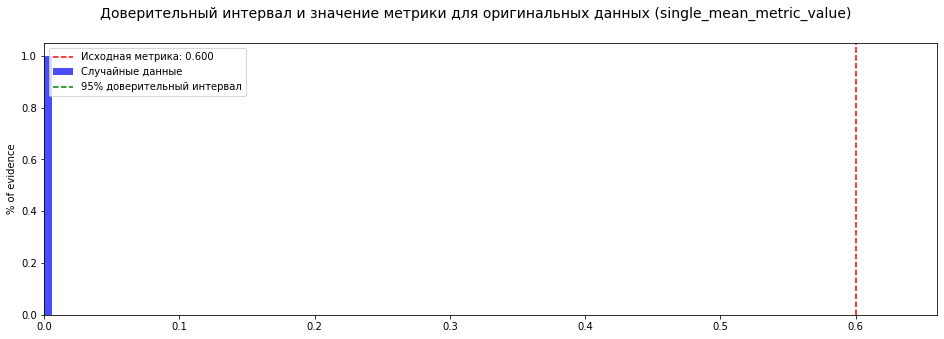

In [31]:
table_mmlu, agg_mmlu = validor.validate(save_res_pkl=True,
                                        save_excel=True)

## Вместо заключения 

Любой инструмент - ничто без тех, кто его использует. Я всегда собираю обратную связь по использованию библиотеки и стараюсь максимально оперативно исправлять то, что можно исправить. Если что-то не получилось, или что-то непонятно (например, после прочтения этого ноутбука!), или есть конкретные предложения, то про это можно: 

A) Написать как комментарий к этой таске: https://jira.delta.sbrf.ru/browse/MFB2DLSN4N-110 

B) Написать мне на почту ialsaenko@sberbank.ru

C) Написать мне в Сберчате - Саенко Иван Александрович

D) Написать мне в телеграм @tigersay1